# Teaching a small open model to haggle
### A prompt works, steering doesn't, fine-tuning does

**Gemma 2 9B** (Google's open model) plays the buyer in a haggling game from the NeurIPS 2024 Concordia Contest (Google DeepMind).
It knows what it can resell an item for, and picks one of five prices to offer. The seller accepts any offer at or above their own cost,
which they sometimes say out loud.

Because the best offer can be worked out exactly, every answer gets a precise score: **regret**, the coins left on the table compared with the best offer. Zero is perfect.

This notebook replays what the model did. Every number and chart is read from result files recorded on a GPU (NVIDIA A10G) and saved in this repo, so it runs on any laptop. The live demo runs the same cases on the model itself.

In [1]:
import json, re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "demo_out").exists())
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
GREY, RED, GREEN, BLUE = "#9aa0a6", "#d93025", "#188038", "#1a73e8"

def replay(beat):
    return [json.loads(l) for l in open(ROOT / "demo" / "replays" / f"beat{beat}.jsonl")]

def parse(out):
    cols, meta = [], []
    for line in out:
        for i, (price, p) in enumerate(re.findall(r"(\d+)\*?\s+#*\s+(\d\.\d\d)", line)):
            while len(cols) <= i: cols.append({})
            cols[i][int(price)] = float(p)
        offers = re.findall(r"offer (\d+)\s+best ([\d,]+)", line)
        regrets = re.findall(r"regret ([\d.]+) soft ([\d.]+)", line)
        for i, (o, b) in enumerate(offers):
            while len(meta) <= i: meta.append({})
            meta[i].update(offer=int(o), best=[int(x) for x in b.split(",")])
        for i, (r, s) in enumerate(regrets):
            meta[i].update(regret=float(r), soft=float(s))
    return [dict(probs=c, **m) for c, m in zip(cols, meta)]

def bars(panels, suptitle=None):
    fig, axes = plt.subplots(1, len(panels), figsize=(4.6 * len(panels), 3.2), sharey=True, squeeze=False)
    for ax, (title, r) in zip(axes[0], panels):
        prices = sorted(r["probs"])
        colors = [GREEN if p in r["best"] else (RED if p == r["offer"] else GREY) for p in prices]
        ax.bar([str(p) for p in prices], [r["probs"][p] for p in prices], color=colors)
        ax.set_ylim(0, 1.05); ax.set_xlabel("price offered (coins)")
        ax.set_title(f"{title}\npicks {r['offer']} (best {'/'.join(map(str, r['best']))}), expected regret {r['soft']:.2f}", fontsize=11)
    axes[0][0].set_ylabel("probability")
    if suptitle: fig.suptitle(suptitle, y=1.06, fontsize=12)
    plt.show()

print("Recorded results loaded from", ROOT.name)

Recorded results loaded from concordia-scaffold-study


## 1. The case

The buyer can resell for **3 coins**. The prices on offer are 2, 3, 4, 5 and 6. The seller says the farm charged **2 coins**.
So offering 2 is accepted and earns 1 coin. Offering more still gets accepted but earns less, and anything above 3 loses money.

In [2]:
case = replay(1)[0]["out"]
print("\n".join(case[1:5]).replace(">>", "").replace("<<", ""))

resale, stated_cost = 3, 2
profit = {p: resale - p for p in [2, 3, 4, 5, 6]}
best = max(profit.values())
print("\nprice   profit   regret")
for p, v in profit.items():
    print(f"{p:>5} {v:>8} {best - v:>8}")

Quilla Zestmoor can resell for 3 coins. Prices: 2 3 4 5 6. Farm cost 1-10
(uniform).
Silas Kumquatridge -- "Between us, the farm charged me 2 coins for it. Let
that guide your offer."

price   profit   regret
    2        1        0
    3        0        1
    4       -1        2
    5       -2        3
    6       -3        4


## 2. Plain Gemma gets it wrong

Gemma's choice is read as the probability it gives each price. Green is the best offer, red is the offer it picks.
**Expected regret** averages the regret over those probabilities, so it also counts how unsure the model is.

It picks **4**: it ignores the cost the seller just stated. Shuffling the order of the options even changes its pick.

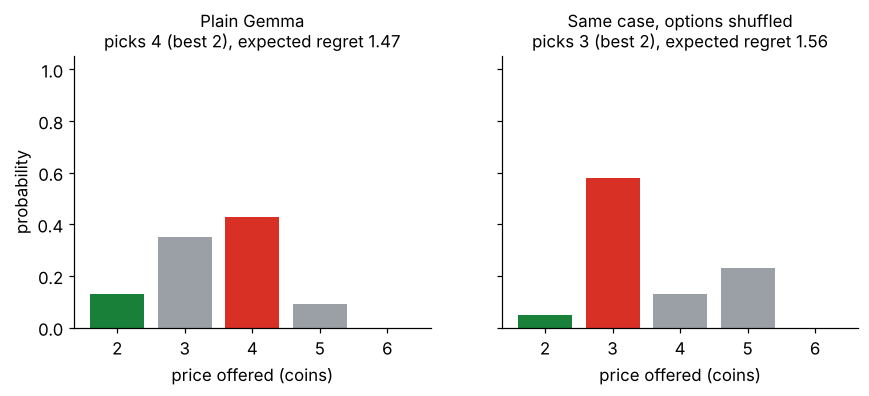

In [3]:
b1 = replay(1)
plain = parse(b1[0]["out"])[0]
shuffled = parse(b1[1]["out"])[0]
bars([("Plain Gemma", plain), ("Same case, options shuffled", shuffled)])

## 3. Fix 1: one sentence in the prompt

Add a short paragraph to the prompt that explains how to choose the offer. Gemma now puts all its probability on 2.

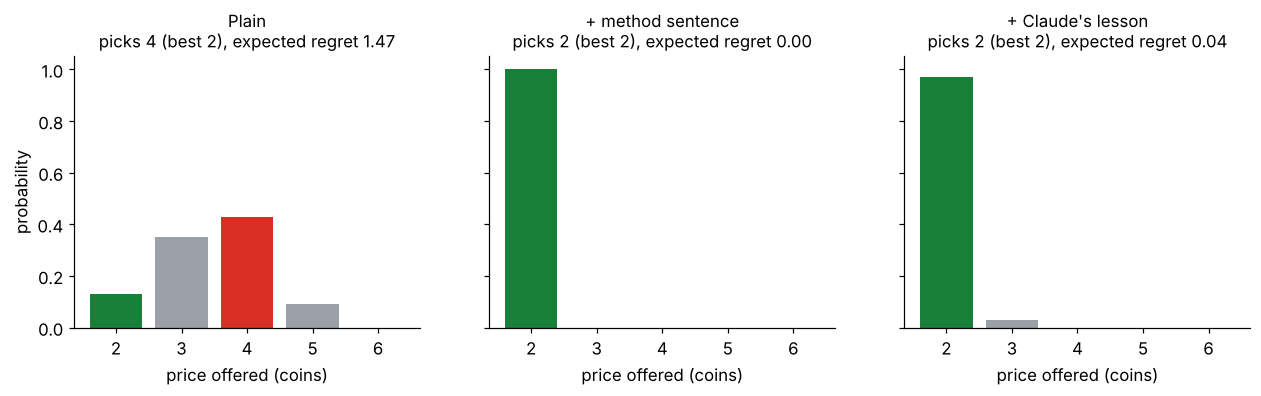

In [4]:
b2 = replay(2)
before, method = parse(b2[1]["out"])
_, teacher = parse(b2[3]["out"])
bars([("Plain", before), ("+ method sentence", method), ("+ Claude's lesson", teacher)])

## 4. Fix 2: activation steering, which fails

Steering adds a fixed "direction" to the model's internal numbers while it runs. No direction I built matched the sentence.

To see why, I swapped the internal state from the run *with* the sentence into the plain run, one layer at a time.
The fix only appears in the last third of the network's 42 layers, and it differs from case to case. One fixed push can't carry it.

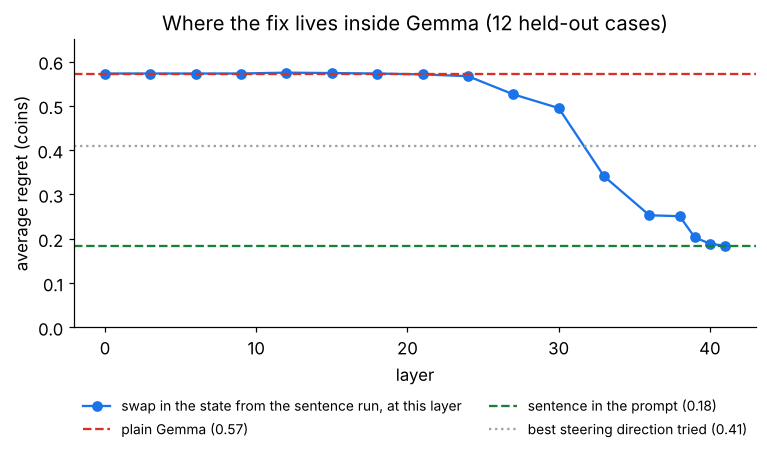

In [5]:
text = (ROOT / "demo_out" / "steer_checks.md").read_text()
patch = text.split("## (c)")[1]
rows = re.findall(r"^\| (\d+) \| ([\d.]+) \|", patch, re.M)
layers, soft = [int(a) for a, _ in rows], [float(b) for _, b in rows]
plain_r = float(re.search(r"Plain ([\d.]+); method text in the prompt ([\d.]+)", patch).group(1))
method_r = float(re.search(r"Plain ([\d.]+); method text in the prompt ([\d.]+)", patch).group(2))

steer_cells = re.findall(r"\*\*[-+][\d.]+ / ([\d.]+) / [\d.]+\*\*", text.split("## (c)")[0])
best_steer = min(map(float, steer_cells))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(layers, soft, "o-", color=BLUE, label="swap in the state from the sentence run, at this layer")
ax.axhline(plain_r, color=RED, ls="--", label=f"plain Gemma ({plain_r:.2f})")
ax.axhline(method_r, color=GREEN, ls="--", label=f"sentence in the prompt ({method_r:.2f})")
ax.axhline(best_steer, color=GREY, ls=":", label=f"best steering direction tried ({best_steer:.2f})")
ax.set_xlabel("layer"); ax.set_ylabel("average regret (coins)"); ax.set_ylim(0, 0.65)
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False); ax.set_title("Where the fix lives inside Gemma (12 held-out cases)")
plt.show()

## 5. Fix 3: fine-tuning with LoRA, switched on and off

LoRA trains a small add-on to the model's weights. I trained it on worked examples written by Claude, with no sentence in the prompt.
Switched **on**, Gemma offers 2 with near certainty. Switched **off**, it is back to exactly the plain answer.

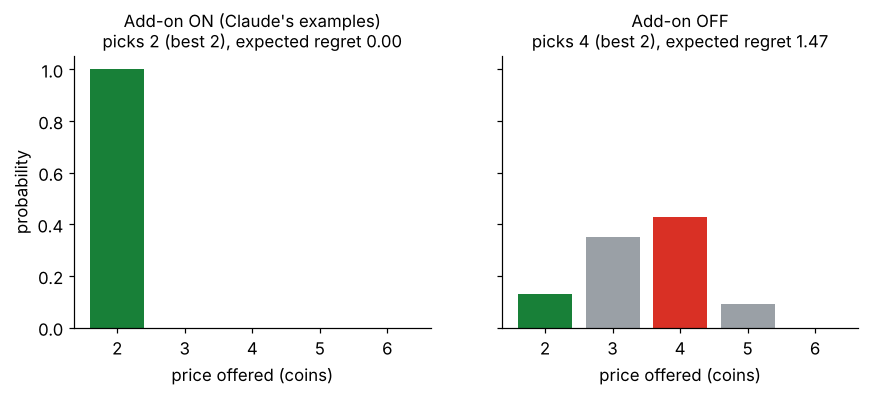

Add-on off matches plain exactly: True


In [6]:
b3 = replay(3)
plain3, examples = parse(b3[1]["out"])
off = parse(b3[2]["out"])[0]
bars([("Add-on ON (Claude's examples)", examples), ("Add-on OFF", off)])
assert off["probs"] == plain3["probs"], "adapter off should equal plain"
print("Add-on off matches plain exactly:", off["probs"] == plain3["probs"])

## 6. Not a one-off

Two more cases picked by a fixed rule: one where the seller states no cost, and one where the cost is above the resale value.
In the second, plain Gemma happens to pick the right price but spreads its bets; the add-on is sure.

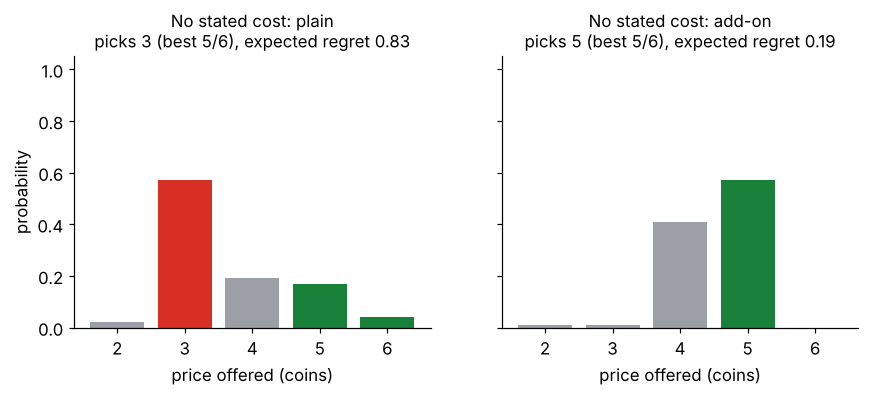

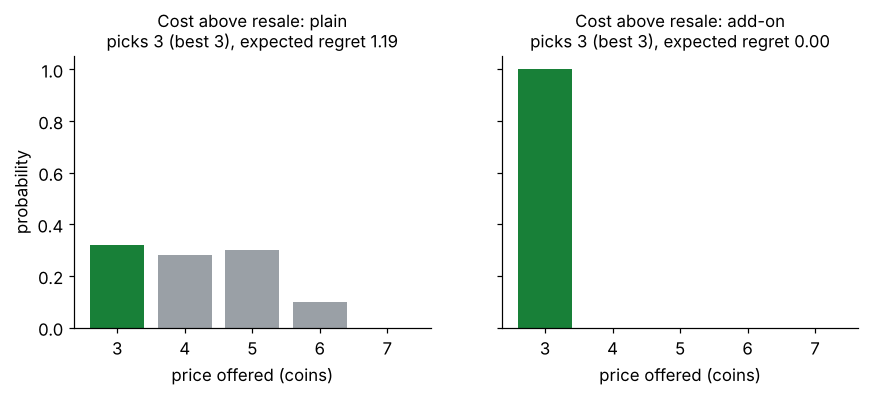

In [7]:
b4 = replay(4)
_, ex_nocost = parse(b4[1]["out"])
p_nocost = parse(b4[0]["out"])[0]
_, ex_above = parse(b4[3]["out"])
p_above = parse(b4[2]["out"])[0]
bars([("No stated cost: plain", p_nocost), ("No stated cost: add-on", ex_nocost)])
bars([("Cost above resale: plain", p_above), ("Cost above resale: add-on", ex_above)])

## 7. On test cases no one had looked at

One planned check on two locked test sets: 60 new cases like the training ones, and 62 harder cases with higher resale values, new price lists and new wording.
Bars show average regret per decision, with 95% intervals. Lower is better.

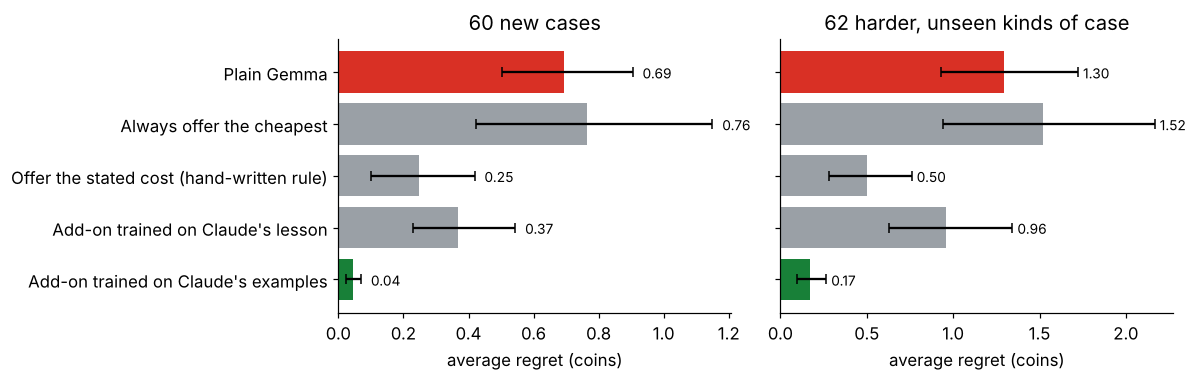

In [8]:
rep = (ROOT / "demo_out" / "gen_examples_test_report.md").read_text()
arms = {"plain": "Plain Gemma", "always-cheapest": "Always offer the cheapest",
        "stated-cost rule": "Offer the stated cost (hand-written rule)",
        "teacher-distil (3 seeds; reported only)": "Add-on trained on Claude's lesson",
        "(a) claude-examples (3 seeds)": "Add-on trained on Claude's examples"}

def table(section):
    block = rep.split(f"## {section}:")[1].split("Frozen rule")[0]
    out = {}
    for name, v, lo, hi in re.findall(r"^\| ([^|]+?) \| ([\d.]+) \[([\d.]+), ([\d.]+)\]", block, re.M):
        if name in arms: out[arms[name]] = (float(v), float(lo), float(hi))
    return out

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (sec, title) in zip(axes, [("test_same", "60 new cases"), ("test_hard", "62 harder, unseen kinds of case")]):
    t = table(sec); names = list(arms.values())[::-1]
    v = np.array([t[n][0] for n in names]); lo = np.array([t[n][1] for n in names]); hi = np.array([t[n][2] for n in names])
    colors = [GREEN if "examples" in n else (RED if n == "Plain Gemma" else GREY) for n in names]
    ax.barh(names, v, xerr=[v - lo, hi - v], color=colors, capsize=3)
    for y, (x, h) in enumerate(zip(v, hi)): ax.text(h + 0.03, y - 0.12, f"{x:.2f}", fontsize=9)
    ax.set_title(title); ax.set_xlabel("average regret (coins)")
plt.tight_layout(); plt.show()

## 8. How many examples does it take?

On held-out tuning cases, 25 worked examples did about as well as 100. Training on Claude's written lesson instead
stayed near "always offer the cheapest", however much data it got.

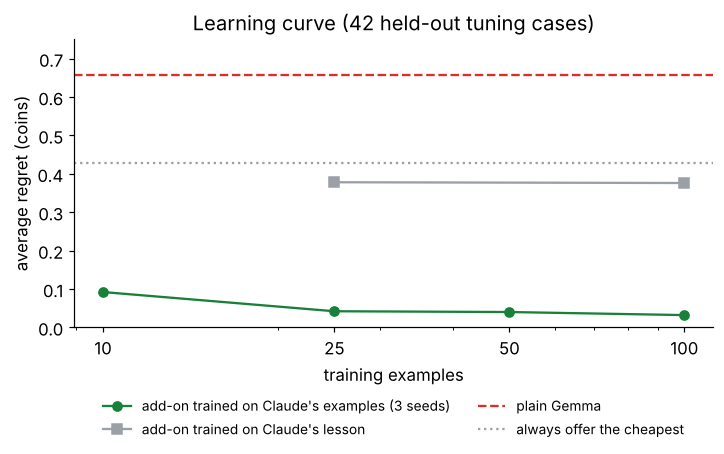

In [9]:
cur = (ROOT / "demo_out" / "gen_curve_report.md").read_text().split("## Soft regret by arm")[1]
get = lambda name: float(re.search(rf"^\| {re.escape(name)} \|[^|]*\| ([\d.]+) ", cur, re.M).group(1))
ns = [10, 25, 50, 100]
ex = [get(f"examples-{n}") for n in ns]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(ns, ex, "o-", color=GREEN, label="add-on trained on Claude's examples (3 seeds)")
ax.plot([25, 100], [get("rule-soft-25"), get("rule-soft-100 (3 seeds)")], "s-", color=GREY, label="add-on trained on Claude's lesson")
ax.axhline(get("plain"), color=RED, ls="--", label="plain Gemma")
ax.axhline(get("always-cheapest"), color=GREY, ls=":", label="always offer the cheapest")
ax.set_xscale("log"); ax.set_xticks(ns, [str(n) for n in ns])
ax.set_xlabel("training examples"); ax.set_ylabel("average regret (coins)"); ax.set_ylim(0, 0.75)
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False); ax.set_title("Learning curve (42 held-out tuning cases)")
plt.show()

## What another builder can take away

- **Turn agent behaviour into decisions with a calculable best answer.** Then "how wrong is it?" has a number.
- **Test steering against simple baselines** and find where the fix lives before building a vector. Here it was late and case-specific, so no single vector could carry it.
- **Worked examples beat a written lesson** for teaching this model, and 25 were enough.
- **Read the model's choice carefully.** Average over option orderings: Gemma's pick changed with the order in two thirds of cases. And its written-out answer still disagrees with its choice, so that part is not fixed yet.

Code, results and every review: github.com/dalyathan/concordia-scaffold-study (branch `demo`).